In [114]:
import pandas as pd
import numpy as np
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [115]:
data=pd.read_excel("employee_data.xlsx")

In [116]:
data=data.head(100)

In [117]:
data.shape

(100, 2)

In [118]:
data.isnull().sum()

Years of Experience    0
Salary                 0
dtype: int64

In [119]:
data.describe()

,Years of Experience,Salary
count,100.000000,100.000000
mean,10.130000,98250.000000
std,7.167061,51695.373257
min,0.000000,30000.000000
25%,3.000000,55000.000000
50%,9.500000,87500.000000
75%,16.000000,130000.000000
max,25.000000,250000.000000


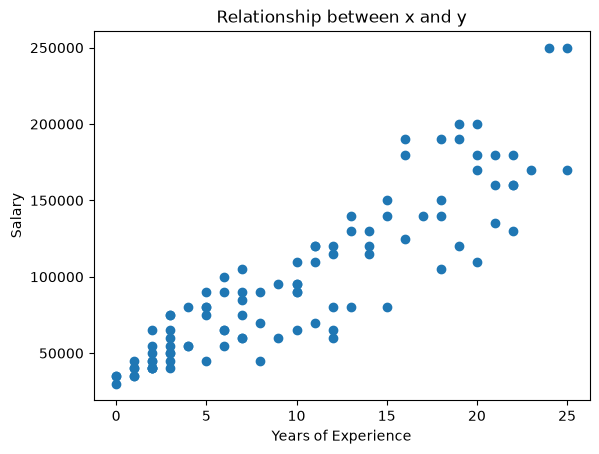

In [120]:
x=data.iloc[:,0]
y=data.iloc[:,1]
plt.scatter(x,y)
plt.xlabel(data.columns[0])
plt.ylabel(data.columns[1])
plt.title("Relationship between x and y")
plt.show()

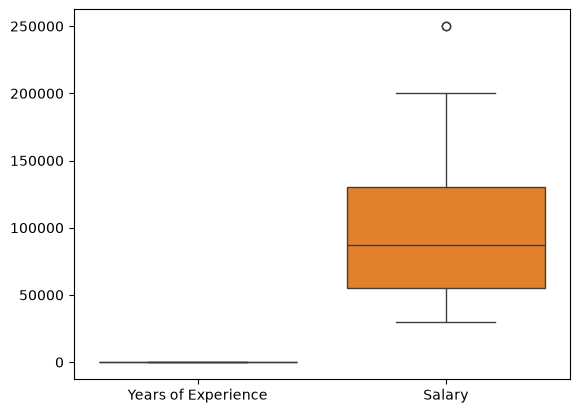

In [121]:
sns.boxplot(data=data)
plt.show()

In [122]:
train_data=data.iloc[:75]
test_data=data.iloc[75:100]

In [123]:
print(train_data.shape)
print(test_data.shape)

(75, 2)
(25, 2)


In [142]:
x_train=train_data[['Years of Experience']]
y_train=train_data[['Salary']]

x_test=test_data[['Years of Experience']]
y_test=test_data[['Salary']]

In [143]:
### ypred = B0 + B1x
### B1=sum((xi-x_avg)*(yi-y_avg))/sum(xi-x_avg)^2
### B0=y_avg - B1*x_avg

In [144]:
# Function to calculate B1
def calc_B1(**args):
    '''Calculates the B1 coefficient (slope) of linear regression using (OLS) method.
       Expects keyword arguments 'x' and 'y'. '''

    # extract x and y from the **args dictionary
    x=args.get('x')
    y=args.get('y')

     # data validation
    if x is None or y is None:
           raise ValueError("Please provide both 'x' and 'y' as keyword arguments")
    if len(x) != len(y):
           raise ValueError("x and y must conatin the same number of data points")

    # calculate x_avg and y_avg
    n = len(x)
    x_avg = sum(x)/n
    y_avg = sum(y)/n

    numerator = sum((xi-x_avg)*(yi-y_avg) for xi, yi in zip(x,y))
    denominator = sum((xi-x_avg)**2 for xi in x)

    if denominator == 0:
        raise ValueError("All x values are identical; slope cannot be determined")

    B1 = numerator/denominator
    return B1
        
        

In [145]:
# Function to calculate B0

def calc_B0(**args):
    ''' Calculates B0, expects argument 'B1', 'x', 'y' '''
    # extract x and y and B1 from args dictionary
    x=args.get('x')
    y=args.get('y')
    B1=args.get('B1')

    n=len(x)
    y_avg = sum(y)/n
    x_avg=sum(x)/n

    B0 = y_avg - B1*x_avg
    return B0
    

In [146]:
print(x_train.dtypes)
print(y_train.dtypes)
print(type(x_train))
print(type(y_train))

Years of Experience    float64
dtype: object
Salary    float64
dtype: object
<class 'pandas.DataFrame'>
<class 'pandas.DataFrame'>


In [147]:
# convert bith pandas dataframe to pandas series
x = x_train.iloc[:, 0]
y = y_train.iloc[:, 0]

print(type(x))  # pandas Series
print(type(y))  # pandas Series

<class 'pandas.Series'>
<class 'pandas.Series'>


In [148]:
B1=calc_B1(x=x,y=y)
B0=calc_B0(x=x,y=y,B1=B1)

print(B0)
print(B1)

32923.86182245881
6808.463107085304


In [149]:
# y = 32923.86182245881 + 6808.463107085304*x

In [150]:
# lets compare these values of B0 and B1 against scikit-learn

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

print("sk_learn B0:", model.intercept_)
print("sl_learn B1:", model.coef_)

sk_learn B0: [32923.86182246]
sl_learn B1: [[6808.46310709]]


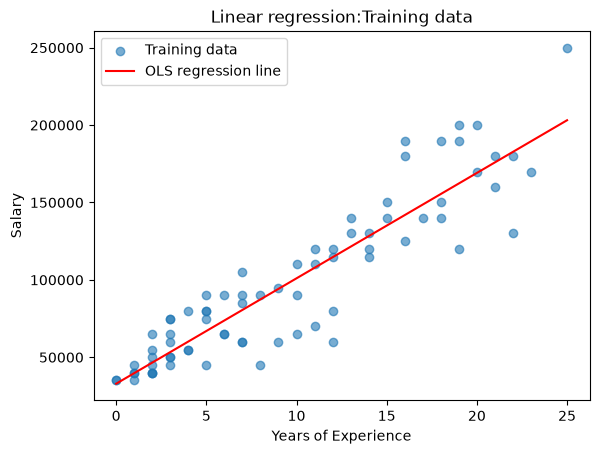

In [151]:
x_line = np.linspace(x.min(), x.max(),100) # generates 100 evenly spaced numbers between minimun experience and maximum experience
y_line= B0 + B1*x_line # calculate predicted salary values
plt.scatter(x,y, label = "Training data", alpha = 0.6)
plt.plot(x_line, y_line, color="red", label = "OLS regression line")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear regression:Training data")
plt.legend()
plt.show()           

## Predict  salaries for the test data

In [152]:
# Extract the test column as series

x_test = x_test.iloc[:,0]
y_test = y_test.iloc[:,0]

# predict using OLS equation
y_pred = B0 + B1 * x_test
print(y_pred)

75    101008.492893
76    182710.050178
77     73774.640465
78    169093.123964
79     53349.251144
80     87391.566679
81    121433.882215
82     32923.861822
83    196326.976393
84     46540.788037
85    101008.492893
86     46540.788037
87    135050.808429
88    175901.587071
89     73774.640465
90    107816.956000
91     53349.251144
92    155476.197750
93    203135.439500
94     80583.103572
95    114625.419107
96    182710.050178
97     39732.324930
98    101008.492893
99    169093.123964
Name: Years of Experience, dtype: float64


### Compare actual salaries with predicted salaries

In [153]:
y_pred = B0 + B1 * x_test

results = pd.DataFrame({
    "Years of Experience": x_test,
    "Actual salary": y_test,
    "Predicted salary": y_pred
})

print(results.head(10))

    Years of Experience  Actual salary  Predicted salary
75                 10.0        95000.0     101008.492893
76                 22.0       160000.0     182710.050178
77                  6.0       100000.0      73774.640465
78                 20.0       180000.0     169093.123964
79                  3.0        55000.0      53349.251144
80                  8.0        70000.0      87391.566679
81                 13.0        80000.0     121433.882215
82                  0.0        30000.0      32923.861822
83                 24.0       250000.0     196326.976393
84                  2.0        40000.0      46540.788037


### Plot actual versus predicted salaries

### Calculate evaluation metrics
#### 1. Mean Absolute Error
#### 2. Mean Squared Error
#### 3. Root Mean Squared Error
#### 4. R^2 errror

In [160]:
# convert pandas series to python lists

actual = y_test.tolist()
predicted = y_pred.tolist()
n=len(y_pred)

errors=[actual[i]-predicted[i] for i in range (n)]

# 1. Mean Absolute Error (MAE)
absolute_errors = [abs(error) for error in errors]
MAE = sum(absolute_errors)/n
print("MAE =", MAE)

# 2. Mean Squared Error (MSE)
squared_error=[error ** 2 for error in errors]
MSE=sum(squared_errors)/n

# 3. root mean squared error (RMSE)
RMSE = MSE ** 0.5



MAE =  22945.49655167147
